In [6]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import torch
import torch.nn as nn


class FrameEncoder(nn.Module):
    def __init__(self, channels, feature_dim, input_size):
        super().__init__()

        if input_size % (2 ** len(channels)) != 0:
            raise ValueError("input_size must be divisible by 2^(number of CNN blocks)")

        layers = []
        in_channels = 3

        for out_channels in channels:
            layers += [
                nn.Conv2d(in_channels, out_channels, 3, stride=2, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True)
            ]
            in_channels = out_channels

        self.conv = nn.Sequential(*layers)
        self.spatial = input_size // (2 ** len(channels))
        self.fc = nn.Linear(channels[-1] * self.spatial ** 2, feature_dim)

    def forward(self, x):
        return self.fc(self.conv(x).flatten(1))


class FrameDecoder(nn.Module):
    def __init__(self, channels, feature_dim, spatial):
        super().__init__()

        self.channels = channels
        self.spatial = spatial
        self.fc = nn.Linear(feature_dim, channels[-1] * spatial ** 2)

        reversed_channels = list(reversed(channels))
        layers = []

        for i in range(len(reversed_channels) - 1):
            layers += [
                nn.ConvTranspose2d(
                    reversed_channels[i], reversed_channels[i + 1],
                    4, stride=2, padding=1
                ),
                nn.BatchNorm2d(reversed_channels[i + 1]),
                nn.ReLU(inplace=True)
            ]

        layers += [
            nn.ConvTranspose2d(reversed_channels[-1], 3, 4, stride=2, padding=1),
            nn.Sigmoid()
        ]

        self.deconv = nn.Sequential(*layers)

    def forward(self, x):
        x = self.fc(x).view(-1, self.channels[-1], self.spatial, self.spatial)
        return self.deconv(x)


class CNNLSTMAutoencoder(nn.Module):
    def __init__(self, config):
        super().__init__()

        channels = config["cnn_channels"]
        feature_dim = config["feature_dim"]
        hidden = config["lstm_hidden"]
        layers = config["lstm_layers"]

        self.encoder = FrameEncoder(channels, feature_dim, config["input_size"])
        self.lstm_encoder = nn.LSTM(feature_dim, hidden, layers, batch_first=True)
        self.lstm_decoder = nn.LSTM(hidden, hidden, layers, batch_first=True)
        self.to_features = nn.Linear(hidden, feature_dim)
        self.decoder = FrameDecoder(channels, feature_dim, self.encoder.spatial)

    def forward(self, x):
        batch, time_steps = x.shape[:2]

        features = self.encoder(x.flatten(0, 1)).view(batch, time_steps, -1)

        _, (hidden, _) = self.lstm_encoder(features)
        code = hidden[-1]

        repeated = code.unsqueeze(1).expand(-1, time_steps, -1).contiguous()
        decoded, _ = self.lstm_decoder(repeated)

        reconstructed = self.decoder(self.to_features(decoded).flatten(0, 1))
        return reconstructed.view_as(x)

sequences: (236, 16, 3, 112, 112)
A_to_A | diff vs model: 4.019483956785308e-07 | bound holds: True
[0.8, 1.43, 2.06, 2.7, 3.18, 3.68, 4.14, 4.58, 5.0, 5.4, 5.77, 6.12, 6.44, 6.73, 6.99, 7.25]
B_to_B | diff vs model: 5.699830162297914e-07 | bound holds: True
[0.79, 1.47, 2.05, 2.61, 3.21, 3.79, 4.33, 4.85, 5.35, 5.82, 6.28, 6.7, 7.11, 7.5, 7.87, 8.22]


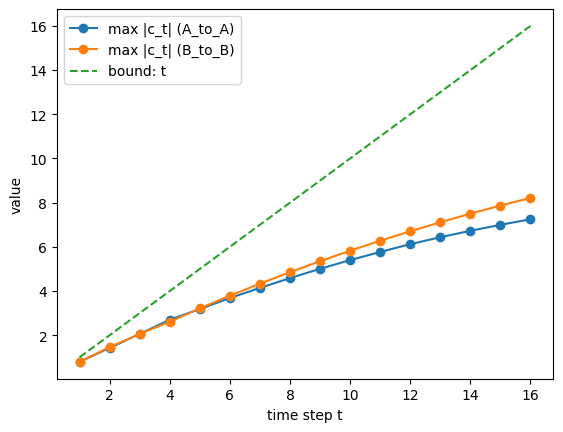

In [8]:
import numpy as np, cv2, torch
from pathlib import Path
import matplotlib.pyplot as plt

PROJECT = Path("/content/drive/MyDrive/CAI421_Project")
DATA_DIR = PROJECT / "data" / "AURA" / "AURA"
CKPT_DIR = PROJECT / "reports" / "cnn_lstm_baseline" / "checkpoints"

def read_window(path, start, length=16, size=112):
    cap = cv2.VideoCapture(str(path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    frames = []
    for _ in range(length):
        ok, f = cap.read()
        if not ok:
            cap.release()
            return None
        f = cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
        f = cv2.resize(f, (size, size), interpolation=cv2.INTER_AREA)
        frames.append(f.astype(np.float32) / 255.0)
    cap.release()
    return np.stack(frames)

X = []
for mp4 in sorted(DATA_DIR.glob("scene_*/videos/*.mp4")):
    for k in range(10):
        w = read_window(mp4, k * 16)
        if w is not None:
            X.append(w)
X = torch.from_numpy(np.stack(X)).permute(0, 1, 4, 2, 3).contiguous()
print("sequences:", tuple(X.shape))

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

results = {}
for name in ["A_to_A", "B_to_B"]:
    ck = torch.load(CKPT_DIR / f"cnn_lstm_{name}.pt",
                    map_location="cpu", weights_only=False)
    model = CNNLSTMAutoencoder(ck["model_config"])
    model.load_state_dict(ck["model_state"])
    model.eval()

    with torch.no_grad():
        n, T = X.shape[:2]
        feats = model.encoder(X.flatten(0, 1)).view(n, T, -1)
        _, (hid, _) = model.lstm_encoder(feats)

    lstm = model.lstm_encoder
    W = lstm.weight_ih_l0.detach().numpy()
    U = lstm.weight_hh_l0.detach().numpy()
    b = (lstm.bias_ih_l0 + lstm.bias_hh_l0).detach().numpy()
    H = U.shape[1]
    feats = feats.numpy()

    h = np.zeros((n, H))
    c = np.zeros((n, H))
    max_c = []
    for t in range(T):
        z = feats[:, t, :] @ W.T + h @ U.T + b
        i = sigmoid(z[:, :H])
        f = sigmoid(z[:, H:2 * H])
        g = np.tanh(z[:, 2 * H:3 * H])
        o = sigmoid(z[:, 3 * H:])
        c = f * c + i * g
        h = o * np.tanh(c)
        max_c.append(float(np.abs(c).max()))

    diff = float(np.abs(h - hid[-1].numpy()).max())
    ok = all(m <= t + 1 for t, m in enumerate(max_c))
    print(name, "| diff vs model:", diff, "| bound holds:", ok)
    print([round(m, 2) for m in max_c])
    results[name] = max_c

steps = np.arange(1, 17)
for name, mc in results.items():
    plt.plot(steps, mc, marker="o", label=f"max |c_t| ({name})")
plt.plot(steps, steps, linestyle="dashed", label="bound: t")
plt.xlabel("time step t")
plt.ylabel("value")
plt.legend()
plt.savefig("cell_state_check.png", dpi=150)
plt.show()